# Two-tower retrieval model

The two-tower model (`yrec.twotower`) embeds users and tracks into one 64-dimensional space. The item tower combines a track ID embedding (with ID dropout, so the tower also learns to represent tracks without one), an artist embedding and an MLP over the 128-dimensional audio embedding. The user tower pools the item vectors of the last 100 listens. Training uses a sampled softmax over in-batch negatives with a log-frequency correction, plus hard negatives re-mined periodically from the model's own nearest neighbours. Retrieval is exact inner-product search over the full catalogue.

This notebook summarises the training runs, compares the main model with the other retrieval sources and examines the cold-start slice.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path('..')
os.environ.setdefault('DATA_DIR', str(ROOT / 'data'))
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from yrec.data import PROC

RES, ART = ROOT / 'results', ROOT / 'artifacts'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b4b2ab', '#52514e'
plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': INK,
    'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.grid': True, 'grid.color': '#e6e5e1',
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.grid.axis': 'y', 'legend.frameon': False, 'font.size': 10,
})
def save(fig, name):
    fig.savefig(FIG / f'{name}.png'); plt.show()

def load(path):
    """Parsed JSON, or None with a short note when the file has not been produced yet."""
    if not path.exists():
        print(f'{path.relative_to(ROOT)} not available yet; the dependent section is skipped.')
        return None
    return json.loads(path.read_text())

VIEWS = ('all', 'discovery')
VIEW_COLOR = {'all': BLUE, 'discovery': AQUA}
SRC = ('tt', 'als', 'audio', 'pop', 'repeat')
NAME = {'tt': 'Two-tower', 'als': 'ALS', 'audio': 'Audio profile', 'pop': 'Popularity', 'repeat': 'Repeat history'}
SRC_COLOR = {'tt': BLUE, 'als': ORANGE, 'audio': AQUA, 'pop': GREY, 'repeat': INK}
def fmt_table(df):
    """3 decimals for recall/NDCG, percent for coverage, en dash for missing."""
    f = {c: '{:.2%}' if 'coverage' in str(c) else '{:.3f}' for c in df.columns}
    return df.style.format(f, na_rep='–')
def bar_labels(ax, bars, vals, fmt='{:.3f}', fontsize=8):
    ax.bar_label(bars, labels=['' if pd.isna(v) else fmt.format(v) for v in vals], padding=2, color=INK, fontsize=fontsize)
notes = []  # one summary bullet per section, filled as sections run

## 1. Training runs

One row per `artifacts/tt_*/config.json`. Throughput counts training examples (one positive each) per second across all GPUs; mining time is the part of the wall time spent re-mining hard negatives. Window-B Recall@100 is only recorded for runs trained on cutoff A with `--eval`.

In [2]:
cfgs = sorted(ART.glob('tt_*/config.json'))
if not cfgs:
    print('No two-tower config.json files available yet; section skipped.')
else:
    runs = pd.DataFrame([{**json.loads(p.read_text()), 'run': p.parent.name} for p in cfgs]).set_index('run')
    runs = runs.reindex(columns=[*runs.columns, *(c for c in ['recall@100', 'mining_time_s'] if c not in runs)])
    tr = pd.DataFrame({
        'cutoff': runs.cutoff, 'audio': ~runs.no_audio.astype(bool), 'hard negatives': ~runs.no_hard_neg.astype(bool),
        'GPUs': runs.world_size, 'steps': runs.steps, 'batch per GPU': runs.batch,
        'examples/s': runs.examples_per_s, 'wall time (min)': runs.wall_time_s / 60,
        'mining share': runs.mining_time_s / runs.wall_time_s, 'final loss': runs.final_loss,
        'window-B Recall@100': runs['recall@100']})
    display(tr.style.format({'examples/s': '{:,.0f}', 'wall time (min)': '{:.1f}', 'mining share': '{:.1%}',
                             'final loss': '{:.3f}', 'window-B Recall@100': '{:.3f}', 'steps': '{:,}'}, na_rep='–'))
    span = lambda c, f: f'{tr[c].min():{f}}' if tr[c].min() == tr[c].max() else f'{tr[c].min():{f}}-{tr[c].max():{f}}'
    msg = (f"{len(tr)} two-tower run{'s' * (len(tr) > 1)}: {span('examples/s', ',.0f')} examples/s and "
           f"{span('wall time (min)', '.0f')} min of training per run; "
           f"hard-negative mining takes at most {tr['mining share'].max():.1%} of wall time.")
    if tr['window-B Recall@100'].notna().any():
        b = tr['window-B Recall@100'].dropna()
        msg += f" Validation (window B) Recall@100: {', '.join(f'{r} {x:.3f}' for r, x in b.items())}."
    print(msg); notes.append(msg)

,cutoff,audio,hard negatives,GPUs,steps,batch per GPU,examples/s,wall time (min),mining share,final loss,window-B Recall@100
run,,,,,,,,,,,
tt_AB_noaudio,AB,False,True,1,"20,000",4096,"58,037",23.5,2.3%,5.331,–


1 two-tower run: 58,037 examples/s and 24 min of training per run; hard-negative mining takes at most 2.3% of wall time.


## 2. Two-tower versus the other learned and baseline sources

Stage-1 metrics of each source's own top-100 list on the test day. Repeat history is left out because it is a lookup rather than a model and does not exist in the discovery view. If the stage-1 file predates the two-tower source, the two-tower row is taken from the standalone evaluation `results/tt_tt_AB.json` (same exclusions and depth).

results/tt_tt_AB.json not available yet; the dependent section is skipped.


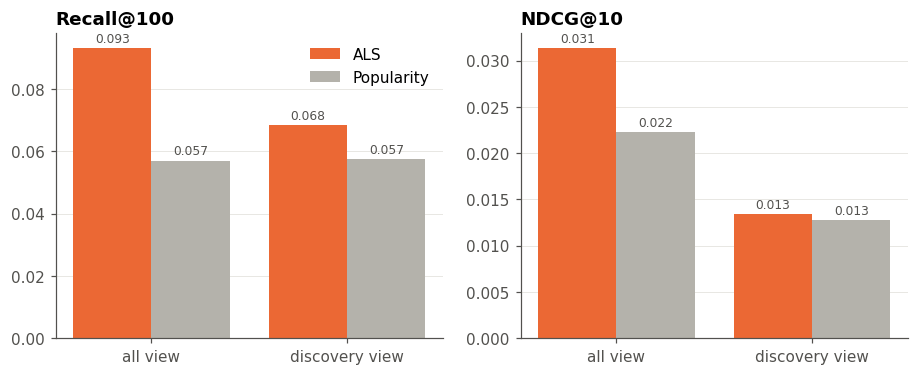

all view: no two-tower metrics available yet.
discovery view: no two-tower metrics available yet.


In [3]:
s1 = {v: load(RES / f'stage1_{v}.json') for v in VIEWS}
tt_main = load(RES / 'tt_tt_AB.json')
cmp = {}
for v, d in s1.items():
    if not d: continue
    src = {s: d['sources'][s] for s in ('tt', 'als', 'audio', 'pop') if s in d['sources']}
    if 'tt' not in src and tt_main:
        src['tt'] = tt_main[v]
    cmp[v] = pd.DataFrame(src).T
if not cmp:
    print('Stage-1 results not available yet; section skipped.')
else:
    MET = ['recall@100', 'ndcg@10', 'coverage@100']
    tab = pd.concat({v: c[MET] for v, c in cmp.items()}, axis=1).reindex([s for s in SRC if any(s in c.index for c in cmp.values())])
    display(fmt_table(tab.rename(index=NAME)))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    srcs = list(tab.index); w = 0.8 / len(srcs); x = np.arange(len(cmp))
    for ax, m in zip(axes, ['recall@100', 'ndcg@10']):
        for j, s in enumerate(srcs):
            vals = [tab.loc[s, (v, m)] for v in cmp]
            b = ax.bar(x + (j - (len(srcs) - 1) / 2) * w, vals, w, color=SRC_COLOR[s], label=NAME[s])
            bar_labels(ax, b, vals)
        ax.set_xticks(x, [f'{v} view' for v in cmp]); ax.set_title(m.replace('recall', 'Recall').replace('ndcg', 'NDCG').replace('coverage', 'Coverage'))
    axes[0].legend(loc='upper right')
    save(fig, '13_two_tower_vs_sources')
    for v in cmp:
        if 'tt' not in tab.index or pd.isna(tab.loc['tt', (v, 'ndcg@10')]):
            print(f'{v} view: no two-tower metrics available yet.')
        else:
            best = tab[(v, 'ndcg@10')].drop('tt').idxmax()
            msg = (f"{v} view: two-tower NDCG@10 {tab.loc['tt', (v, 'ndcg@10')]:.3f} and Recall@100 {tab.loc['tt', (v, 'recall@100')]:.3f} "
                   f"versus {NAME[best]} (the strongest other source) at {tab.loc[best, (v, 'ndcg@10')]:.3f} and "
                   f"{tab.loc[best, (v, 'recall@100')]:.3f}, a {tab.loc['tt', (v, 'ndcg@10')] / tab.loc[best, (v, 'ndcg@10')] - 1:+.0%} NDCG@10 difference.")
            print(msg); notes.append(msg)

## 3. Cold-start tracks

The cold slice keeps only discovery targets whose track had no listens before the cutoff, for users with at least one such target. Such tracks have an untrained ID embedding, so the item tower must rely on artist and audio features. Rankings are over the full catalogue with the user's history excluded, as in the discovery view.

In [4]:
if not tt_main:
    print('Main two-tower evaluation (results/tt_tt_AB.json) not available yet; section skipped.')
else:
    sl = pd.DataFrame({k: tt_main[k] for k in ('all', 'discovery', 'cold')}).T
    cols = [f'{m}@{k}' for m in ('recall', 'ndcg') for k in (10, 50, 100)]
    display(fmt_table(sl[cols + ['users']]).format({'users': '{:,.0f}'}))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    x, w = np.arange(3), 0.27
    for j, (k, c) in enumerate(zip(sl.index, [BLUE, AQUA, ORANGE])):
        vals = [sl.loc[k, f'recall@{n}'] for n in (10, 50, 100)]
        b = ax.bar(x + (j - 1) * w, vals, w, color=c, label=f'{k} ({sl.loc[k, "users"]:,.0f} users)')
        bar_labels(ax, b, vals)
    ax.set_xticks(x, ['Recall@10', 'Recall@50', 'Recall@100']); ax.legend(loc='upper left')
    ax.set_title('Main two-tower model by target slice')
    save(fig, '14_two_tower_cold_start')
    msg = (f"Cold-start slice ({tt_main['cold']['targets']:,} target pairs, {sl.loc['cold', 'users']:,.0f} users): two-tower "
           f"Recall@100 {sl.loc['cold', 'recall@100']:.3f} versus {sl.loc['discovery', 'recall@100']:.3f} on all discovery targets "
           f"({sl.loc['cold', 'recall@100'] / sl.loc['discovery', 'recall@100']:.0%} of the warm-and-cold level).")
    print(msg); notes.append(msg)

Main two-tower evaluation (results/tt_tt_AB.json) not available yet; section skipped.


## Summary

Bullet points below are computed from the result files in the cells above.

In [5]:
display(Markdown('\n'.join(f'- {n}' for n in notes) if notes else '- No result files were available when this notebook ran.'))

- 1 two-tower run: 58,037 examples/s and 24 min of training per run; hard-negative mining takes at most 2.3% of wall time.